---
title: "Caravella, Barbieri and Drioli (2009): concentration polarisation in Pd membranes, and what a film coefficient misses along a laminar tube"
description: "The paper's concentration polarisation coefficient comes from a local film model with a length-averaged Sherwood correlation; a resolved 2-D laminar tube with a Sieverts wall tests whether that film describes the loss of driving force along a module, and the paper's printed numbers are checked."
categories: [sec:H, struct:S6, tier:T1, data:tier6, phase:gas]
date: 2026-11-27
---

# Caravella, Barbieri and Drioli (2009): concentration polarisation along a laminar Pd-membrane tube

**Catalog ID:** `H1.3` · **Structures:** `S6` (2-D steady, marched along the tube) · **Tier:** T1

A Pd membrane passes only hydrogen. From an H2/N2 mixture the hydrogen that permeates
leaves the nitrogen behind at the wall, so the H2 partial pressure the membrane sees is
lower than in the bulk: concentration polarisation. Caravella, Barbieri and Drioli
(2009) measure it by a coefficient, CPC (Eq. 13), the fraction of the bulk Sieverts
driving force lost in the gas film, computed from a film model at "a generic point of the
tube-in-tube membrane purifier" (p. 615) with a Sherwood number from Eq. (9). They then
read their maps along a module: "the results are valid in every position of the
separation equipment" (p. 618). In the laminar branch, Eq. (9) is a Lévêque coefficient
averaged over the module length. This page solves the problem the paper does not: a
resolved 2-D laminar tube with radial diffusion, the suction of the permeating hydrogen
and the nonlinear Sieverts wall flux, marched along the module. It asks whether the
film with the averaged coefficient describes the loss of driving force along the tube
(the module total and the local CPC), and checks the paper's printed numbers.

The catalogue also cites a later paper (Int. J. Hydrogen Energy, 2015); it is not
available to this page, and nothing here comes from it.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.7"  # replaced by the release tag at publication
PYMRM = ">=3.4.1,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "H1.3-pd-membrane-concentration-polarisation"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. pymrm contributes the 2-D march (operators, NumJac, newton) and the checks
# (find_roots, observed_orders); the film relations are scalar roots.
import contextlib
import io
import math
import re
from dataclasses import dataclass, field, replace

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from model import (LEVEQUE_AVG, LEVEQUE_LOCAL, TubeMarch, cpc_zero_flux, film_cpc, film_module,
                   film_xs, graetz_lambda0, unique_root, z_bernoulli)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        return format(v[name], fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

Palladium-alloy membranes separate hydrogen from mixtures; for thin membranes the
permeance is high enough that the gas side, not the metal, limits the flux. The paper
combines a six-component Stefan-Maxwell film (Eqs. 1 to 9) with a multi-step membrane
model (Table 2, parameters in the authors' Ref. [9]) and maps CPC over temperature,
thickness, the two pressures, the H2 fraction and the Reynolds number (Figs. 3 to 9).
The maps are in the turbulent branch of Eq. (9) (Table 4); the one laminar case is the
validation against Peters et al. (Table 5, Fig. 10), where the authors note an H2 partial
pressure depletion along the module and computed "each point of the model ... as
arithmetic mean of the two fluxes evaluated at the inlet and outlet of the membrane
module" (p. 623).

What the page can decide. The paper does not print its diffusivities, viscosity or module
length (searched: text, tables, captions, nomenclature; viscosity and hydraulic diameter
appear as symbols only), so its maps cannot be re-solved, and they are out of scope here. What can be decided is whether its film relation, with the coefficient of
Eq. (9), describes a laminar tube point by point; that needs a resolved solve, which is
the page's own extension. The siblings cover the rest: `H1.1` the Sieverts closure and
the permeator, `H1.4` the membrane reactor; this page owns the gas-side boundary layer.

## The published model

As printed (pp. 615 to 617), with the readings the page uses:

| Eq. | Printed | Read as |
|---|---|---|
| (1) | $\vec N = \frac{1}{RT}\{Kc\}\cdot\{Z\}\cdot(\vec P^{Bulk}\vec P^{Surface}) + \frac{N_{Total}}{P_{Total}}\vec P^{Surface}$ | the minus sign is missing (M1); Table 2 prints $(P^{Bulk} - P^{Surface})$ |
| (5) | $B_{ij} = -x(1/D_{ij} - 1/D_{in})$ | $x_i$ (M2); not needed for a binary |
| (6) | $\{Z\} = \{\varphi\}(e^{\{\varphi\}} = \{I\})^{-1}$, $\{\varphi\} = \frac{RT N_{Total}}{P_{Total}}\{Kc\}^{-1}$ | "=" for "−" (M3), confirmed by Eq. (7) |
| (7) | $\{Z\} \cong \{I\} - \frac12\{\varphi\} + \frac1{12}\{\varphi\}^2$ | the series of Eq. (6) |
| (3), (8) | $Sh = g(Re)Sc^q$, $Kc = \nu^r g(Re) D^{1-q}/d_h$ | $q$, $r$ not given (M4); $q = r = 1/3$, as both branches of Eq. (9) are standard forms with $Sc^{1/3}$ |
| (9) | $g(Re) = 1.62\,(d_{Equivalent}Re/L)^{1/3}$ for $Re \le 2100$; $0.026\,Re^{0.80}$ above | the laminar branch is the Lévêque coefficient averaged over $0..L$ |
| (13) | $CPC = 1 - \frac{H_2flux}{\pi^{Membrane}\,\Delta\sqrt{P_{H_2}}\big|^{Bulk}}$ | with Sieverts' law, $CPC = 1 - \frac{\sqrt{x_s} - \sqrt\theta}{\sqrt{x_b} - \sqrt\theta}$ |

**M5, the reference state of Eq. (6).** Film theory gives $Z = \varphi(e^\varphi - 1)^{-1}$
when the convective term carries the starting (bulk) composition and
$\varphi(1 - e^{-\varphi})^{-1}$ when it carries the end (surface) composition. Eq. (1) puts
the surface fraction in the convective term and Eq. (6) is the bulk form. The page cannot
tell which the authors coded: R5 measures the difference and the page builds on the exact
film, $n = \ln\frac{1 - x_s}{1 - x_b}$.

**The reduced model** (binary H2/N2, N2 inert, isothermal and isobaric, Sieverts at the
wall, the paper's ideal-membrane limit). In units of $c k$:
$n = \beta(\sqrt{x_s} - \sqrt\theta)$, $\beta = \Pi\sqrt P/(ck) = 2\,Da/Sh$,
$\theta = p_{perm}/P$, $Da = \Pi\sqrt P R/(cD)$. At zero flux ($x_b \to \theta$) the film
CPC tends to $G/(1 + G)$ with $G = \beta(1 - \theta)/(2\sqrt\theta)$, finite and the same
from either side: the paper's "the bulk permeance tends to a finite value, which is the
same one found for the back-flux case" (p. 617), here in the reduced model.

**The 2-D tube** (the page's extension). Radius $R$, $\xi = r/R$, $\zeta = z/L$, a developed
parabolic profile kept along the tube (low suction), continuity giving the radial flow:

$$\frac{Gz}{4}\frac{\partial[a(\xi) f x]}{\partial\zeta} + \frac1\xi\frac{\partial}{\partial\xi}\Big[\xi\big(\nu_w w(\xi)x - \frac{\partial x}{\partial\xi}\big)\Big] = 0,\qquad
  \frac{df}{d\zeta} = -\frac{8\nu_w}{Gz},$$

$a = 2(1 - \xi^2)$, $w = 2\xi - \xi^3$, $f(0) = 1$, $x(\xi, 0) = x_{in}$; at the wall
$-\partial x/\partial\xi = \nu_w(1 - x_w)$ (no N2 flux) with
$\nu_w = Da(\sqrt{x_w} - \sqrt\theta)$; $Gz = \bar u d^2/(DL) = Re\,Sc\,d/L$. The local 2-D
CPC uses the cup-mean fraction as the bulk. **The 1-D route** is the paper's film made into
a module: plug flow, the film at the local bulk fraction with a Sherwood number $Sh$,
$dx_b/d\zeta = -8\nu(1 - x_b)^2/((1 - x_{in})Gz)$. With $\beta = 2Da/Sh$ both routes are
defined by $(x_{in}, \theta, Gz, Da)$. Three film coefficients are compared: (a) Eq. (9)'s
average $C_{avg}Gz^{1/3}$, (b) the local Lévêque value $C_{loc}(Gz/\zeta)^{1/3}$ and
(c) the developed value $Sh_\infty$.

## Parameters and assumptions

The test condition (TC) takes its inputs from Table 5's validation: $x_{in}$ from "50:50", $\theta$ from
the printed permeate pressure at a feed of 20 bar (inside the printed feed range), and
$Gz$, $Da$ chosen so that the 2-D partial pressure depletion falls inside the paper's
depletion range and the inlet film CPC near Fig. 10's level. Nothing else is taken from
the paper; diffusivity, viscosity and module length are not printed (searched: text,
tables, captions, nomenclature; viscosity and hydraulic diameter appear as symbols only).

**Assumptions (not the paper's).** The Schmidt number of H2:N2 50:50 at 400 °C enters only
to turn a Graetz number into a length, $L/d = Re\,Sc/Gz$, and the wall Reynolds number; the
page uses the range 0.25 to 0.45, an estimate from typical gas properties, not a value
read from any source. The mixture viscosity for the M9 length is likewise an assumed
typical gas value; the length is proportional to it. Every conclusion that rests on them
carries its range.

In [3]:
PN = load_data("caravella-2009-printed-numbers.csv", page=PAGE, dtype=str, keep_default_na=False)
RD = load_data("caravella-2009-fig10-model-reads.csv", page=PAGE)
print(cite_data(load_meta("caravella-2009-printed-numbers.csv", page=PAGE)))
print(cite_data(load_meta("caravella-2009-fig10-model-reads.csv", page=PAGE)))


def printed(pn, item):
    """A printed entry, as the string printed."""
    return pn.loc[pn["item"] == item, "printed"].iloc[0]


def num(pn, item):
    """A printed number as a float."""
    return float(printed(pn, item))


def half_unit(s):
    """Half a unit of the last printed digit of the string ``s``."""
    return 0.5 * 10.0 ** -(len(s.split(".")[1]) if "." in s else 0)


def half_unit_flux(s):
    """Half a unit of the last significant digit of ``s``: the trailing zeros of a printed
    integer (a rounded reading such as 1880) are read as placeholders, so 1880 has half unit 5."""
    if "." in s:
        return half_unit(s)
    return 0.5 * 10.0 ** (len(s) - len(s.rstrip("0")))


X_IN = 0.5                                        # H2:N2 50:50 (Table 5)
P_FEED_TC = 20.0                                  # bar, inside Table 5's 3 to 26 bar (page's choice)
THETA = num(PN, "t5_pperm_bar") / P_FEED_TC       # permeate/feed pressure ratio
GZ_TC, DA_TC = 500.0, 25.0                        # page's test condition
BETA = 2.0 * DA_TC / (LEVEQUE_AVG * GZ_TC ** (1.0 / 3.0))   # film beta with Eq. (9)'s average
SC_RANGE = (0.25, 0.45)                           # assumption, see the text
MU_ASSUMED = 3.0e-5                               # Pa s, assumed mixture viscosity (M9 only)
M_MIX = 0.5 * 2.016e-3 + 0.5 * 28.013e-3          # kg/mol, H2:N2 50:50
TC_LEVELS = ((50, 100), (100, 200), (200, 400))   # (radial cells, axial steps), both refined by 2
SW_LEVELS = ((25, 50), (50, 100), (100, 200))     # the same for the Gz sweep
GZ_WIN = (1.0, 3000.0)                            # Graetz window of R2
say("TC: $x_{in}$ = <<x>>, $\\theta$ = <<t>>/<<p:g>> = <<th:.5f>>, $Gz$ = <<g:g>>, $Da$ = <<d:g>>, "
    "so $\\beta$ = <<b:.5f>>. Printed: permeate <<t>> bar, feed <<f1>> to <<f2>> bar, $Re$ about "
    "<<re>>, depletion <<d1>> to <<d2>> %.",
    x=X_IN, t=printed(PN, "t5_pperm_bar"), p=P_FEED_TC, th=THETA, g=GZ_TC, d=DA_TC, b=BETA,
    f1=printed(PN, "t5_pfeed_lo"), f2=printed(PN, "t5_pfeed_hi"), re=printed(PN, "t5_re"),
    d1=printed(PN, "depl_lo_pct"), d2=printed(PN, "depl_hi_pct"))

Caravella, A.; Barbieri, G.; Drioli, E. (2009) — Separation and Purification Technology 66, 613-624 — doi:10.1016/j.seppur.2009.01.008 — table
Caravella, A.; Barbieri, G.; Drioli, E. (2009) — Separation and Purification Technology 66, 613-624 — doi:10.1016/j.seppur.2009.01.008 — digitised from Fig. 10a (model curve, 'Results of the present model') and Fig. 10b (model points), p. 623


TC: $x_{in}$ = 0.5, $\theta$ = 1.01/20 = 0.05050, $Gz$ = 500, $Da$ = 25, so $\beta$ = 3.90045. Printed: permeate 1.01 bar, feed 3 to 26 bar, $Re$ about 115, depletion 4 to 7 %.

## The data

The paper reports no data of its own; the page uses two files. The printed numbers
(strings, compared in half-units of their last printed digit): Eq. (9)'s constants,
Tables 4 and 5, the depletion and CPC ranges of p. 623, Fig. 9's four reference fluxes and
Fig. 10's printed percentages. The figure reads: the model's flux and CPC in Fig. 10 at
its four dashed guides, read from the 200 ppi embedded image (reading error in the
sidecar). Figs. 3 to 9 are not digitised. The `check_values.csv` rows are computed by a
second route from the same equations, not read from the paper.

## PyMRM implementation

`model.TubeMarch` marches the 2-D tube in $\zeta$.

- **Grid.** Radial faces $\xi = s(1 + 0.8(1 - s))$ with $s$ uniform: cells nine times finer
  at the wall than at the axis, and a refinement is nested. Axial steps $\zeta_j = (j/K)^3$:
  the inlet layer grows as $\zeta^{1/3}$, smooth in $j$.
- **Operators**, assembled once: `construct_grad` and `construct_div(nu=1)` (cylindrical)
  for radial diffusion; the suction flux $\nu_w w(\xi)x$ with the central face value, the
  mean of two `construct_convflux_upwind` operators for $\pm w$. Cell weights $a$ are exact
  cell means over the cylindrical volumes, so continuity and the N2 balance hold to
  round-off.
- **Boundary conditions**, outward normal: axis $-\partial x/\partial\xi = 0$
  (`{a: 1, b: 0, d: 0}`); wall $x = x_w$ (`{a: 0, b: 1, d: 1}` with `shapes_d`, the wall
  value an unknown). The wall row is the physics: $-\partial x/\partial\xi = \nu_w(1 - x_w)$
  with $\nu_w$ by Sieverts' law. Wall values and gradients are read by
  `compute_boundary_values` under the same bc.
- **Unknowns per step**: $x$ on the cells (shape $(n, 1)$) bordered by $x_w$ and the flow
  $f$; variable-step BDF2 (backward Euler on the first step), each step one `pymrm.newton`
  solve with the bordered Jacobian; `NumJac((1, 1))` differentiates the Sieverts flux.
- **Every 2-D number is extrapolated**: three levels with cells and steps refined
  together, Richardson with the observed order (`pymrm.checks.observed_orders`); the split
  ladders are in the Validation.
- **The 1-D route** (`model.film_module`) integrates the film module with scipy DOP853;
  the film is solved for $x_s$ by `find_roots`, exactly one root.

In [4]:
@dataclass(frozen=True)
class Cfg:
    """Everything the study reads; every break row changes one field."""
    pn: object = field(default_factory=lambda: PN)
    rd: object = field(default_factory=lambda: RD)
    sh1d: str = "avg"            # 1-D route coefficient: Eq. (9) exact average, 'printed' 1.62, 'local'
    loc_const: float = LEVEQUE_LOCAL   # constant of the local Leveque film (b)
    stefan: bool = True          # suction and the (1 - x_w) factor at the wall
    profile: str = "parabolic"   # axial velocity profile of the 2-D solve
    conv: str = "central"        # face value of the suction flux
    gz_ax: float = 1.0           # factor on Gz in the axial term only (a defect when not 1)
    film_r5: str = "printed"     # R5: Eq. (1) with Eq. (6) as printed
    g_stefan: bool = True        # zero-flux closed form with (1 - theta)
    f10_pperm: float = 101.0     # kPa, permeate H2 partial pressure of the Fig. 10 consistency check
    mu: float = MU_ASSUMED       # Pa s, assumed viscosity (M9)
    sc: tuple = SC_RANGE         # assumed Schmidt range
    beta_r2: float = BETA        # the fixed film beta of the R2 sweep
    scheme: str = "bdf2"         # axial step
    tol: float = 1e-11           # newton step tolerance
    comp_tol: float = 1e-13      # newton tolerance of the companion run
    comp_da: float = 1.0         # Da factor of the companion run (a defect when not 1)


C0 = Cfg()
CACHE = {}


def march(c, gz, da, n, k, profile=None, wall="sieverts", tol=None, stefan=None):
    """One 2-D march, cached on everything that defines it."""
    key = (gz, da, n, k, profile or c.profile, wall, tol or c.tol, c.stefan if stefan is None else stefan,
           c.conv, c.gz_ax, c.scheme)
    if key not in CACHE:
        CACHE[key] = TubeMarch(X_IN, THETA, gz, da, n=n, k=k, profile=profile or c.profile, wall=wall,
                               stefan=c.stefan if stefan is None else stefan, conv=c.conv,
                               gz_axial=gz * c.gz_ax, scheme=c.scheme, tol=tol or c.tol).run()
    return CACHE[key]


def extrap(vals):
    """Richardson extrapolation over three levels refined by 2 (scalars or arrays)."""
    v = dict(zip((1, 2, 4), vals))
    return observed_orders(lambda i: np.asarray(v[i], dtype=float), (1, 2, 4))


def sh_1d(c, gz):
    """Sherwood number of the 1-D route: Eq. (9)'s average (exact or printed) or the local constant."""
    const = {"avg": LEVEQUE_AVG, "printed": num(c.pn, "eq9_lam_const"), "local": LEVEQUE_LOCAL}[c.sh1d]
    return const * gz ** (1.0 / 3.0)


def da_of(c, gz):
    """Da at fixed beta (R2): the film beta of Eq. (9)'s average equals ``c.beta_r2``."""
    return c.beta_r2 * LEVEQUE_AVG * gz ** (1.0 / 3.0) / 2.0


def crossing(c, h):
    """zeta where the 2-D local CPC equals the averaged-coefficient film CPC at the local cup mean.

    The step values are joined by a cubic spline in s = zeta^(1/3) (uniform in the step index);
    the root is found with find_roots (exactly one) between the first step and the outlet.
    """
    s = h.zeta[1:] ** (1.0 / 3.0)
    d = h.cpc_local() - np.array([film_cpc(x, BETA, THETA) for x in h.x_cup[1:]])
    spl = CubicSpline(s, d)
    return unique_root(lambda t: float(spl(t)), s[0], 1.0, n_scan=200) ** 3


def tc_level(c, h, cross=True):
    """The TC quantities of one 2-D level (the R1 crossing only when ``cross``)."""
    q = {"rec": h.recovery(), "x_out": h.x_cup[-1], "f_out": h.f[-1], "cpc": h.cpc_local()[-1],
         "xw": h.x_w[-1], "nu_out": h.nu[-1], "nu_mean": GZ_TC / 8.0 * (1.0 - h.f[-1]),
         "depl": 1.0 - h.x_cup[-1] / X_IN}
    if cross:
        q["cross"] = crossing(c, h)
    return q


def tc_extrap(c, profile=None, stefan=None, cross=True):
    """The TC quantities extrapolated over TC_LEVELS, with error estimates and orders."""
    L = [tc_level(c, march(c, GZ_TC, DA_TC, n, k, profile=profile, stefan=stefan), cross)
         for n, k in TC_LEVELS]
    out = {}
    for q in L[0]:
        o = extrap([l[q] for l in L])
        out[q], out[q + "_est"], out[q + "_order"] = o["extrapolated"], o["error_estimate"], o["orders"][-1]
    return out

The study: every number the page reports, for one configuration. The break table reruns
parts of it with one field of `Cfg` changed.

In [5]:
def part_closed(c, M):
    """Constants of the film relations, Eq. (9)'s printed constant, Eq. (7)'s range (R5)."""
    M["c_leveque_local"], M["c_leveque_avg"] = LEVEQUE_LOCAL, LEVEQUE_AVG
    lam = graetz_lambda0()
    M["c_graetz_lambda0"], M["c_sh_inf"] = lam, lam ** 2 / 2.0
    M["c_gz_star"] = (M["c_sh_inf"] / LEVEQUE_AVG) ** 3
    s = printed(c.pn, "eq9_lam_const")
    g = abs(float(s) - LEVEQUE_AVG) / half_unit(s)
    M["c_eq9_in_print"], M["c_eq9_in_print__margin"] = bool(g <= 1.0), abs(1.0 - g)
    M["r5_phi_1pc"] = unique_root(lambda p: z_bernoulli(p, "eq7") / z_bernoulli(p) - 1.01, 0.05, 3.0)


def part_r3(c, M):
    """Fig. 9: membrane permeance from each printed reference flux (CPC = 0 at x = 1)."""
    df = math.sqrt(num(c.pn, "f9_pret_kpa") * 1e3) - math.sqrt(num(c.pn, "f9_pperm_kpa") * 1e3)
    M["r3_df_ref"] = df
    pid = {}
    for i in range(1, 5):
        d = int(num(c.pn, f"f9_delta_{i}"))
        pi = num(c.pn, f"f9_flux_{i}") * 1e-3 / df
        M[f"r3_pi_{d}um"], pid[i] = pi, pi * d * 1e-6
        M[f"r3_pid_{d}um"] = pid[i]
    M["r3_spread_pct"] = 100.0 * (max(pid.values()) / min(pid.values()) - 1.0)
    # pairs against the thickest membrane: gap / (half-units of the two printed fluxes; the
    # trailing zeros of a printed integer are placeholders, see half_unit_flux)
    ratios = []
    for i in (1, 2, 3):
        s1, s4 = printed(c.pn, f"f9_flux_{i}"), printed(c.pn, "f9_flux_4")
        allow = half_unit_flux(s1) / float(s1) + half_unit_flux(s4) / float(s4)
        ratios.append(abs(pid[i] / pid[4] - 1.0) / allow)
    M["r3_n_exceed"] = int(sum(r > 1.0 for r in ratios))
    M["r3_n_exceed__margin"] = float(min(abs(r - 1.0) for r in ratios))
    M["r3_worst_ratio"] = float(max(ratios))
    M["_r3_n_pairs"] = len(ratios)


def part_r4(c, M):
    """Zero-flux limit of the film CPC: closed form against root solves on either side."""
    th = num(c.pn, "t5_pperm_bar") / P_FEED_TC            # from the printed permeate pressure
    M["r4_cpc0"] = cpc_zero_flux(BETA, th, c.g_stefan)
    for side, e in (("fwd", 1e-6), ("back", -1e-6)):
        M[f"r4_cpc0_gap_{side}"] = abs(film_cpc(th * (1.0 + e), BETA, th) - M["r4_cpc0"])


def part_r5(c, M):
    """Eq. (1) with Eq. (6) as printed (M5) against the exact film, at TC and over x_b."""
    th = num(c.pn, "t5_pperm_bar") / P_FEED_TC            # from the printed permeate pressure
    M["r5_cpc_exact"] = film_cpc(X_IN, BETA, th)
    M["r5_cpc_printed"] = film_cpc(X_IN, BETA, th, c.film_r5)
    M["r5_cpc_linear"] = film_cpc(X_IN, BETA, th, "linear")
    M["r5_gap_tc"] = M["r5_cpc_printed"] - M["r5_cpc_exact"]
    gap = lambda xb: film_cpc(xb, BETA, th, c.film_r5) - film_cpc(xb, BETA, th)
    xs = np.linspace(th * 1.02, 0.99, 60)
    d = np.diff([gap(x) for x in xs])
    M["r5_n_gap_increasing"] = int(np.sum(d > 0))
    M["_r5_n_intervals"] = len(d)
    M["r5_n_gap_increasing__margin"] = float(np.min(np.abs(d)) / np.max(np.abs(d)))
    M["r5_gap_099"] = gap(0.99)


def part_r6(c, M):
    """Fig. 10 (figure reads): membrane permeance implied by Eq. (10); the M9 length."""
    rd = c.rd
    p = rd["P_feed_bar"].to_numpy() * 1e5
    n, k = rd["model_flux_mol_m2_s"].to_numpy(), rd["model_CPC"].to_numpy()
    def pi_of(pp):
        return 1e3 * n / ((1.0 - k) * (np.sqrt(X_IN * p) - math.sqrt(pp * 1e3)))
    pi = pi_of(c.f10_pperm)
    M["r6_pi_first"], M["r6_pi_last"] = pi[0], pi[-1]
    M["r6_drop_pct"] = 100.0 * (1.0 - pi[-1] / pi[0])
    rel = 0.005 / n + 0.005 / (1.0 - k)              # sidecar reading error, relative, per point
    M["r6_read_err_pct"] = 100.0 * (rel[0] + rel[-1])
    M["r6_drop_over_err"] = M["r6_drop_pct"] / M["r6_read_err_pct"]
    g = lambda pp: pi_of(pp)[0] / pi_of(pp)[-1] - 1.0
    pe = unique_root(g, 0.0, 0.99 * X_IN * p.min() / 1e3, n_scan=200, xtol=1e-9)
    M["r6_pperm_equal_kpa"] = pe
    M["r6_spread_at_equal_pct"] = 100.0 * (pi_of(pe).max() / pi_of(pe).min() - 1.0)
    flux = float(rd.loc[rd["P_feed_bar"] == 20, "model_flux_mol_m2_s"].iloc[0])
    for tag in ("lo", "hi"):
        dep = num(c.pn, f"depl_{tag}_pct") / 100.0
        x_out = X_IN * (1.0 - dep)
        rec = 1.0 - (1.0 - X_IN) / (1.0 - x_out) * x_out / X_IN
        M[f"r6_L_mm_{tag}"] = 1e3 * rec * num(c.pn, "t5_re") * c.mu * X_IN / (4.0 * flux * M_MIX)


def part_tc(c, M):
    """R1 at TC: 2-D against the film module and the local films."""
    T = tc_extrap(c)
    M["r1_rec_2d"], M["r1_rec_2d_est"] = T["rec"], T["rec_est"]
    M["r1_x_out_2d"], M["r1_f_out_2d"] = T["x_out"], T["f_out"]
    M["r1_cpc_2d"], M["r1_cpc_2d_est"] = T["cpc"], T["cpc_est"]
    M["r1_xw_2d"], M["r1_nu_out_2d"], M["r1_nu_mean_2d"] = T["xw"], T["nu_out"], T["nu_mean"]
    M["r1_depl_pct"] = 100.0 * T["depl"]
    lo, hi = num(c.pn, "depl_lo_pct"), num(c.pn, "depl_hi_pct")
    M["r1_depl_inside"] = bool(lo <= M["r1_depl_pct"] <= hi)
    M["r1_depl_inside__margin"] = min(M["r1_depl_pct"] - lo, hi - M["r1_depl_pct"]) / (hi - lo)
    M["r1_cross_zeta"], M["r1_cross_est"] = T["cross"], T["cross_est"]
    M["r1_cross_leveque"] = (c.loc_const / LEVEQUE_AVG) ** 3
    m1 = film_module(X_IN, THETA, GZ_TC, DA_TC, sh_1d(c, GZ_TC))
    M["r1_rec_1d"], M["r1_cpc_out_1d"], M["r1_x_out_1d"] = m1["recovery"], m1["cpc_out"], m1["x_out"]
    M["r1_rec_gap_pct"] = 100.0 * (M["r1_rec_1d"] / M["r1_rec_2d"] - 1.0)
    md = film_module(X_IN, THETA, GZ_TC, DA_TC, graetz_lambda0() ** 2 / 2)
    M["_r1_rec_1d_dev"] = md["recovery"]
    b = 2.0 * DA_TC / sh_1d(c, GZ_TC)
    nu_in = DA_TC * (math.sqrt(film_xs(X_IN, b, THETA)) - math.sqrt(THETA))
    M["r1_nu_in_film"], M["r1_nu_recipe"] = nu_in, 0.5 * (nu_in + m1["nu_out"])
    M["r1_recipe_gap_pct"] = 100.0 * (M["r1_nu_recipe"] / M["r1_nu_mean_2d"] - 1.0)
    x2 = M["r1_x_out_2d"]
    M["r1_cpc_avg_film"] = film_cpc(x2, BETA, THETA)
    M["r1_sh_local_out"] = c.loc_const * GZ_TC ** (1.0 / 3.0)
    M["r1_cpc_local_film"] = film_cpc(x2, 2.0 * DA_TC / M["r1_sh_local_out"], THETA)
    M["r1_cpc_gap_avg"] = M["r1_cpc_avg_film"] - M["r1_cpc_2d"]
    M["r1_cpc_gap_local"] = M["r1_cpc_local_film"] - M["r1_cpc_2d"]
    M["r1_rewall_lo"], M["r1_rewall_hi"] = M["r1_nu_mean_2d"] / c.sc[1], M["r1_nu_mean_2d"] / c.sc[0]
    M["v2_n2_balance"] = max(march(c, GZ_TC, DA_TC, n, k).n2_balance() for n, k in TC_LEVELS)


def part_sens(c, M):
    """V5: plug flow and the low-flux wall, one at a time, and the R1 gaps under plug flow."""
    for tag, kw in (("plug", {"profile": "plug"}), ("lowflux", {"stefan": False})):
        T = tc_extrap(c, cross=False, **kw)
        M[f"v5_{tag}_rec_change_pct"] = 100.0 * (T["rec"] / M["r1_rec_2d"] - 1.0)
        M[f"v5_{tag}_cpc_change"] = T["cpc"] - M["r1_cpc_2d"]
        if tag == "plug":
            M["v5_plug_rec_gap_pct"] = 100.0 * (M["r1_rec_1d"] / T["rec"] - 1.0)
            M["v5_plug_cpc_gap_avg"] = film_cpc(T["x_out"], BETA, THETA) - T["cpc"]


def part_v(c, M):
    """V1 Graetz limit and V4 split ladders at TC, with the solver-tolerance companion."""
    gz_g = 4.0          # long tube: the outlet is developed; tolerance far below the decayed x
    hs = [march(c, gz_g, 0.0, n, 400, wall="dirichlet", tol=1e-16) for n, _ in TC_LEVELS]
    o = extrap([h.sherwood_local()[-1] for h in hs])
    M["v1_graetz_sh_gap"] = abs(o["extrapolated"] / (graetz_lambda0() ** 2 / 2.0) - 1.0)
    M["_v1_graetz_order"] = o["orders"][-1]
    q = lambda h: np.array([h.recovery(), h.cpc_local()[-1]])
    rad = extrap([q(march(c, GZ_TC, DA_TC, n, 400)) for n, _ in TC_LEVELS])
    ax = extrap([q(march(c, GZ_TC, DA_TC, 200, k)) for _, k in TC_LEVELS])
    rv, av = rad["values"], ax["values"]
    for tag, v in (("n", rv), ("k", av)):
        d1, d2 = np.abs(v[0] - v[1]), np.abs(v[1] - v[2])
        M[f"v4_order_{tag}_rec"], M[f"v4_order_{tag}_cpc"] = np.log2(d1 / d2)
        M[f"_v4_finest_diff_{tag}"] = float(np.min(d2))
    base = q(march(c, GZ_TC, DA_TC, 200, 400))
    tight = q(march(c, GZ_TC, DA_TC * c.comp_da, 200, 400, tol=c.comp_tol))
    M["v4_tol_effect"] = float(np.max(np.abs(base - tight)))
    M["v4_finest_over_tol"] = min(M["_v4_finest_diff_n"], M["_v4_finest_diff_k"]) / max(M["v4_tol_effect"], 1e-16)


def r2_vals(c, gz, lv):
    """2-D depletion and the 1-D recovery error (fraction) at fixed beta, on sweep level ``lv``."""
    n, k = SW_LEVELS[lv]
    h = march(c, gz, da_of(c, gz), n, k)
    rec1 = film_module(X_IN, THETA, gz, da_of(c, gz), sh_1d(c, gz))["recovery"]
    return 1.0 - h.x_cup[-1] / X_IN, rec1 / h.recovery() - 1.0


def r2_root(c, i, target, window, n_scan=10):
    """Root in ln Gz of quantity ``i`` minus ``target``: unique on the middle level over ``window``,
    then on each level in a narrow window around it; extrapolated over the levels."""
    t = unique_root(lambda t: r2_vals(c, math.exp(t), 1)[i] - target, *window, n_scan=n_scan, xtol=1e-7)
    roots = [unique_root(lambda u: r2_vals(c, math.exp(u), lv)[i] - target, t - 0.05, t + 0.05,
                         n_scan=3, xtol=1e-7) for lv in range(3)]
    o = extrap(roots)
    return math.exp(o["extrapolated"]), o["error_estimate"]


W_FULL = (math.log(GZ_WIN[0]), math.log(GZ_WIN[1]))


def part_r2dep(c, M):
    """R2: Graetz numbers where the 2-D depletion equals the printed 4 and 7 % (one root each)."""
    for tag in ("lo", "hi"):
        g, e = r2_root(c, 0, num(c.pn, f"depl_{tag}_pct") / 100.0, W_FULL)
        M[f"r2_gz_depl_{tag}"], M[f"_r2_gz_depl_{tag}_est"] = g, e
    M["r2_Ld_min"] = num(c.pn, "t5_re") * c.sc[0] / M["r2_gz_depl_lo"]
    M["r2_Ld_max"] = num(c.pn, "t5_re") * c.sc[1] / M["r2_gz_depl_hi"]


def part_r2ext(c, M):
    """R2: the most negative 1-D recovery error (scan, then bounded minimisation on the middle level)."""
    ts = np.linspace(*W_FULL, 10)
    e = [r2_vals(c, math.exp(t), 1)[1] for t in ts]
    i = int(np.argmin(e))
    if i in (0, len(ts) - 1):
        raise ValueError("error extremum at the window end")
    r = minimize_scalar(lambda t: r2_vals(c, math.exp(t), 1)[1], bounds=(ts[i - 1], ts[i + 1]),
                        method="bounded", options={"xatol": 1e-3})
    o = extrap([r2_vals(c, math.exp(r.x), lv)[1] for lv in range(3)])
    M["r2_err_ext_pct"], M["r2_err_ext_gz"] = 100.0 * o["extrapolated"], math.exp(r.x)
    M["_r2_t_ext"] = r.x


def part_r2err(c, M):
    """R2: the Gz where the 1-D recovery error crosses -2 % and -5 %, one root on each side."""
    if "_r2_t_ext" not in M:
        part_r2ext(c, M)
    t = M["_r2_t_ext"]
    for pct in (2, 5):
        for side, win in (("lo", (W_FULL[0], t)), ("hi", (t, W_FULL[1]))):
            g, e = r2_root(c, 1, -pct / 100.0, win, n_scan=6)
            M[f"r2_gz_err{pct}_{side}"], M[f"_r2_gz_err{pct}_{side}_est"] = g, e


PARTS = {"closed": part_closed, "r3": part_r3, "r4": part_r4, "r5": part_r5, "r6": part_r6,
         "tc": part_tc, "sens": part_sens, "v": part_v, "r2dep": part_r2dep, "r2ext": part_r2ext,
         "r2err": part_r2err}


def study(c, parts=tuple(PARTS)):
    """Every number the page reports, for one configuration."""
    M = {}
    for p in parts:
        PARTS[p](c, M)
    return M


M = study(C0)
print(f"study: {len(CACHE)} marches")   # wall time is not printed: it differs run to run

study: 167 marches


Before any claim, the page's functions are asserted against check values computed by a
second route (closed forms, scipy quadrature and a scipy method-of-lines 2-D solve, no
pymrm and no page code; `data/check_values.meta.yaml`).

In [6]:
FIG9 = {f"Pi_membrane_fig9_{d}um": M[f"r3_pi_{d}um"] for d in (5, 15, 50, 100)}
FIG9.update({f"Pi_times_delta_fig9_{d}um": M[f"r3_pid_{d}um"] for d in (5, 15, 50, 100)})
m_dev = film_module(X_IN, THETA, GZ_TC, DA_TC, M["c_sh_inf"])
CV = {"DF_ref_Pa05": M["r3_df_ref"], **FIG9,
      "x_zero_flux_1000_200kPa": num(PN, "f9_pperm_kpa") / num(PN, "f9_pret_kpa"),
      "leveque_local_const": M["c_leveque_local"], "leveque_avg_const": M["c_leveque_avg"],
      "graetz_lambda0": M["c_graetz_lambda0"], "graetz_Sh_inf": M["c_sh_inf"],
      "Gz_leveque_equals_Sh_inf": M["c_gz_star"], "phi_eq7_error_1pc": M["r5_phi_1pc"],
      "TC_Sh_leveque_avg": LEVEQUE_AVG * GZ_TC ** (1 / 3), "TC_beta": BETA,
      "TC_film_exact_xs": film_xs(X_IN, BETA, THETA), "TC_film_exact_CPC": M["r5_cpc_exact"],
      "TC_film_printed_xs": film_xs(X_IN, BETA, THETA, "printed"), "TC_film_printed_CPC": M["r5_cpc_printed"],
      "TC_film_printed_eq7_xs": film_xs(X_IN, BETA, THETA, "printed_eq7"),
      "TC_film_printed_eq7_CPC": film_cpc(X_IN, BETA, THETA, "printed_eq7"),
      "TC_film_linear_xs": film_xs(X_IN, BETA, THETA, "linear"), "TC_film_linear_CPC": M["r5_cpc_linear"],
      "TC_CPC_zero_flux_limit": M["r4_cpc0"],
      "TC_1D_leveque_x_out": M["r1_x_out_1d"], "TC_1D_leveque_recovery": M["r1_rec_1d"],
      "TC_1D_leveque_CPC_out": M["r1_cpc_out_1d"], "TC_1D_developed_x_out": m_dev["x_out"],
      "TC_1D_developed_recovery": M["_r1_rec_1d_dev"], "TC_1D_developed_CPC_out": m_dev["cpc_out"],
      "TC_2D_x_cup_out": M["r1_x_out_2d"], "TC_2D_f_out": M["r1_f_out_2d"], "TC_2D_recovery": M["r1_rec_2d"],
      "TC_2D_CPC_out": M["r1_cpc_2d"], "TC_2D_x_wall_out": M["r1_xw_2d"], "TC_2D_nu_wall_out": M["r1_nu_out_2d"],
      "TC_2D_nu_mean": M["r1_nu_mean_2d"], "TC_2D_pH2_depletion": M["r1_depl_pct"] / 100.0,
      "TC_film_leveque_nu_inlet": M["r1_nu_in_film"], "TC_film_leveque_nu_recipe_mean": M["r1_nu_recipe"],
      "TC_Sh_leveque_local_out": M["r1_sh_local_out"],
      "TC_film_avg_leveque_CPC_at_2D_out": M["r1_cpc_avg_film"],
      "TC_film_local_leveque_CPC_at_2D_out": M["r1_cpc_local_film"]}
with contextlib.redirect_stdout(io.StringIO()):
    DEV = assert_check_values(CV, page=PAGE)
say("Check values: <<n:d>> of <<t:d>> rows agree, each inside its own tolerance; the largest "
    "relative deviation of a 2-D row is <<w:.1e>>.",
    n=len(DEV), t=len(CV), w=max(abs(v) for k, v in DEV.items() if k.startswith("TC_2D")))

Check values: 46 of 46 rows agree, each inside its own tolerance; the largest relative deviation of a 2-D row is 3.5e-07.

## Results

### R1. At the test condition: the module total against the local CPC

The 2-D solve against the 1-D film module with Eq. (9)'s averaged coefficient (the
recovery is the permeated fraction of the inlet H2), and the local CPC at the outlet from
the film at the 2-D cup-mean fraction with the averaged, the local Lévêque and the
developed coefficient.

In [7]:
say("2-D partial pressure depletion <<d:.3f>> %, inside the paper's <<a>> to <<b>> % "
    "(<<i>>). Recovery: 2-D <<r2:.5f>>, 1-D with the averaged coefficient <<r1:.5f>> "
    "(<<g:+.3f>> %). Module-mean flux "
    "$\\bar\\nu$: 2-D <<n2:.4f>>; the paper's recipe, the mean of the film flux at inlet and "
    "outlet, <<nr:.4f>> (<<ng:+.3f>> %).",
    d=M["r1_depl_pct"], a=printed(PN, "depl_lo_pct"), b=printed(PN, "depl_hi_pct"),
    i=M["r1_depl_inside"], r2=M["r1_rec_2d"], r1=M["r1_rec_1d"], g=M["r1_rec_gap_pct"],
    n2=M["r1_nu_mean_2d"], nr=M["r1_nu_recipe"], ng=M["r1_recipe_gap_pct"])
say("Outlet CPC: 2-D <<c2:.4f>>; film with the averaged coefficient <<ca:.4f>> (<<ga:+.4f>>), "
    "with the local Lévêque coefficient ($Sh$ = <<sl:.3f>>) <<cl:.4f>> (<<gl:+.4f>>). The 2-D "
    "local CPC equals the averaged-coefficient film at $\\zeta$ = <<z:.4f>> (Richardson error "
    "estimate <<ze:.1e>>); pure Lévêque theory puts it at $(C_{loc}/C_{avg})^3$ = <<zl:.4f>>. "
    "Upstream of it the averaged film overstates the polarisation, downstream it understates it.",
    c2=M["r1_cpc_2d"], ca=M["r1_cpc_avg_film"], ga=M["r1_cpc_gap_avg"], sl=M["r1_sh_local_out"],
    cl=M["r1_cpc_local_film"], gl=M["r1_cpc_gap_local"], z=M["r1_cross_zeta"],
    ze=M["r1_cross_est"], zl=M["r1_cross_leveque"])

2-D partial pressure depletion 5.677 %, inside the paper's 4 to 7 % (True). Recovery: 2-D 0.10744, 1-D with the averaged coefficient 0.10802 (+0.534 %). Module-mean flux $\bar\nu$: 2-D 3.3575; the paper's recipe, the mean of the film flux at inlet and outlet, 3.3761 (+0.552 %).

Outlet CPC: 2-D 0.8008; film with the averaged coefficient 0.7203 (-0.0805), with the local Lévêque coefficient ($Sh$ = 8.546) 0.8029 (+0.0021). The 2-D local CPC equals the averaged-coefficient film at $\zeta$ = 0.3326 (Richardson error estimate 3.2e-05); pure Lévêque theory puts it at $(C_{loc}/C_{avg})^3$ = 0.2963. Upstream of it the averaged film overstates the polarisation, downstream it understates it.

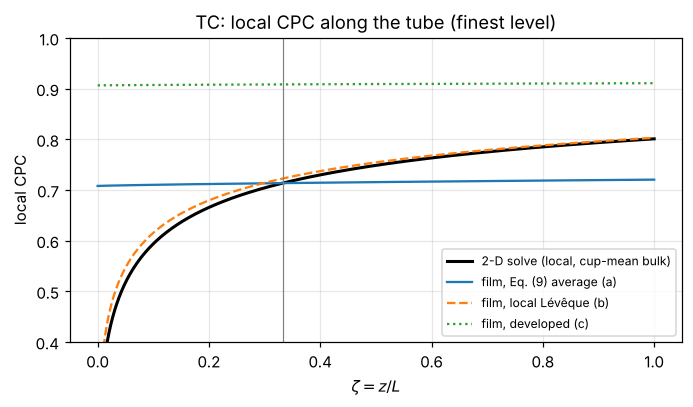

In [8]:
h = march(C0, GZ_TC, DA_TC, *TC_LEVELS[-1])
z, xc = h.zeta[1:], h.x_cup[1:]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(z, h.cpc_local(), "k", lw=2, label="2-D solve (local, cup-mean bulk)")
ax.plot(z, [film_cpc(x, BETA, THETA) for x in xc], label="film, Eq. (9) average (a)")
ax.plot(z, [film_cpc(x, 2 * DA_TC / (LEVEQUE_LOCAL * (GZ_TC / zz) ** (1 / 3)), THETA) for x, zz in zip(xc, z)],
        "--", label="film, local Lévêque (b)")
ax.plot(z, [film_cpc(x, 2 * DA_TC / M["c_sh_inf"], THETA) for x in xc], ":", label="film, developed (c)")
ax.axvline(M["r1_cross_zeta"], color="0.5", lw=0.8)
ax.set_xlabel(r"$\zeta = z/L$"); ax.set_ylabel("local CPC"); ax.set_ylim(0.4, 1.0)
ax.legend(fontsize=8); ax.set_title("TC: local CPC along the tube (finest level)")
fig.tight_layout(); plt.show()

The wall Reynolds number $v_wR/\nu = \nu_w/Sc$ is well above one here, outside the
small-suction range in which the parabolic profile is exact; the plug-flow profile is the
other extreme. V5 swaps it in and says whether the R1 finding survives.

In [9]:
say("Wall Reynolds number from the 2-D module-mean flux: <<a:.2f>> to <<b:.2f>> over the "
    "assumed $Sc$ range. With a plug profile (V5) the 1-D recovery gap is <<p:+.3f>> % and the "
    "outlet CPC gap of the averaged film <<q:+.4f>>; with the parabolic profile <<r:+.3f>> % "
    "and <<s:+.4f>>. The plug profile changes the 2-D recovery by <<u:+.3f>> % and the outlet "
    "CPC by <<v:+.4f>>; dropping the suction and the $(1 - x_w)$ factor changes them by "
    "<<w:+.3f>> % and <<y:+.4f>>.",
    a=M["r1_rewall_lo"], b=M["r1_rewall_hi"], p=M["v5_plug_rec_gap_pct"], q=M["v5_plug_cpc_gap_avg"],
    r=M["r1_rec_gap_pct"], s=M["r1_cpc_gap_avg"], u=M["v5_plug_rec_change_pct"], v=M["v5_plug_cpc_change"],
    w=M["v5_lowflux_rec_change_pct"], y=M["v5_lowflux_cpc_change"])

Wall Reynolds number from the 2-D module-mean flux: 7.46 to 13.43 over the assumed $Sc$ range. With a plug profile (V5) the 1-D recovery gap is -43.595 % and the outlet CPC gap of the averaged film +0.0854; with the parabolic profile +0.534 % and -0.0805. The plug profile changes the 2-D recovery by +78.236 % and the outlet CPC by -0.1556; dropping the suction and the $(1 - x_w)$ factor changes them by -30.478 % and +0.0608.

### R2. Over the Graetz number, at fixed $\beta$

$\beta$ is held at its TC value (the averaged film has the same inlet CPC everywhere) and
$Gz$ runs over the window below. Every threshold is a root in $\ln Gz$ (`find_roots`,
exactly one in its window, then once per level and extrapolated). Every point outside the
paper's depletion range is outside its validation conditions.

In [10]:
say("The 2-D depletion equals the printed <<a>> % at $Gz$ = <<g1:.2f>> and <<b>> % at "
    "$Gz$ = <<g2:.2f>>. With the printed $Re$ <<re>> and the assumed $Sc$ range, the paper's "
    "depletion corresponds to $L/d$ between <<l1:.4f>> and <<l2:.4f>> for a laminar tube.",
    a=printed(PN, "depl_lo_pct"), g1=M["r2_gz_depl_lo"], b=printed(PN, "depl_hi_pct"), g2=M["r2_gz_depl_hi"],
    re=printed(PN, "t5_re"), l1=M["r2_Ld_min"], l2=M["r2_Ld_max"])
say("The error of the 1-D recovery with the averaged coefficient is not monotone in $Gz$. Its "
    "most negative value is <<e:.3f>> % near $Gz$ = <<ge:.2f>> (bounded minimisation on the "
    "middle level, value extrapolated); $Sh_{avg}$ falls below $Sh_\\infty$ at $Gz^*$ = "
    "<<gs:.4f>>. It reaches -2 % at $Gz$ = <<a:.3f>> and <<b:.3f>>, and -5 % at <<c:.3f>> and "
    "<<d:.3f>>. Below the first root both routes approach equilibrium at the outlet and agree "
    "again. The paper's depletion range lies at $Gz$ = <<h:.2f>> to <<l:.2f>>, outside both "
    "bands, so outside its validation conditions; over the scanned window the module total "
    "misses by more than 2 % only between the two -2 % roots (one root on each side of the "
    "minimum).",
    e=M["r2_err_ext_pct"], ge=M["r2_err_ext_gz"], gs=M["c_gz_star"], a=M["r2_gz_err2_lo"],
    b=M["r2_gz_err2_hi"], c=M["r2_gz_err5_lo"], d=M["r2_gz_err5_hi"],
    h=M["r2_gz_depl_hi"], l=M["r2_gz_depl_lo"])

The 2-D depletion equals the printed 4 % at $Gz$ = 845.87 and 7 % at $Gz$ = 365.53. With the printed $Re$ 115 and the assumed $Sc$ range, the paper's depletion corresponds to $L/d$ between 0.0340 and 0.1416 for a laminar tube.

The error of the 1-D recovery with the averaged coefficient is not monotone in $Gz$. Its most negative value is -5.366 % near $Gz$ = 10.78 (bounded minimisation on the middle level, value extrapolated); $Sh_{avg}$ falls below $Sh_\infty$ at $Gz^*$ = 11.6066. It reaches -2 % at $Gz$ = 4.204 and 31.903, and -5 % at 8.262 and 14.276. Below the first root both routes approach equilibrium at the outlet and agree again. The paper's depletion range lies at $Gz$ = 365.53 to 845.87, outside both bands, so outside its validation conditions; over the scanned window the module total misses by more than 2 % only between the two -2 % roots (one root on each side of the minimum).

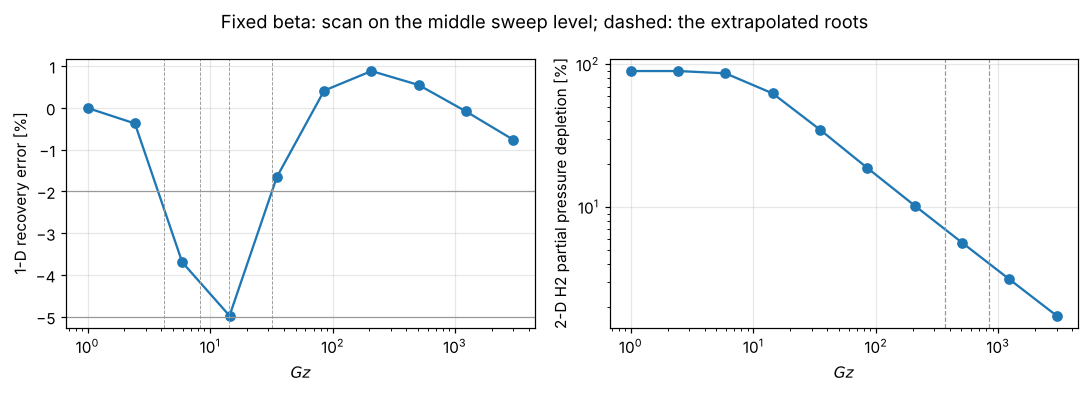

In [11]:
gzs = np.exp(np.linspace(*W_FULL, 10))
vals = np.array([r2_vals(C0, g, 1) for g in gzs])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].semilogx(gzs, 100 * vals[:, 1], "o-")
for p_ in (2, 5):
    axs[0].axhline(-p_, color="0.6", lw=0.8)
    for s_ in ("lo", "hi"):
        axs[0].axvline(M[f"r2_gz_err{p_}_{s_}"], color="0.6", lw=0.6, ls="--")
axs[0].set_xlabel("$Gz$"); axs[0].set_ylabel("1-D recovery error [%]")
axs[1].loglog(gzs, 100 * vals[:, 0], "o-")
for t_ in ("lo", "hi"):
    axs[1].axvline(M[f"r2_gz_depl_{t_}"], color="0.6", lw=0.8, ls="--")
axs[1].set_xlabel("$Gz$"); axs[1].set_ylabel("2-D H2 partial pressure depletion [%]")
fig.suptitle("Fixed beta: scan on the middle sweep level; dashed: the extrapolated roots")
fig.tight_layout(); plt.show()

### R3. Fig. 9's printed reference fluxes

At $x_{H_2} = 1$ there is no film, so CPC = 0 and the membrane permeance is the printed flux
over the Sieverts driving force at the caption's pressures. For a bulk-limited membrane the
permeance scales as $1/\delta$; the thicknesses are the simulation's set values, the fluxes
are rounded results.

In [12]:
for d in (5, 15, 50, 100):
    print(f"{d:4d} um  Pi = {1e3 * M[f'r3_pi_{d}um']:.5f} mmol m-2 s-1 Pa-0.5   Pi*delta = {M[f'r3_pid_{d}um']:.5e}")
say("$\\Pi\\delta$ spreads by <<s:.3f>> % over the four panels. Against the thickest membrane, "
    "<<n:d>> of <<N:d>> pairs differ by more than the half-units of their two printed fluxes "
    "(largest: <<w:.3f>> allowances, the thinnest membrane). A half-unit is half of the last "
    "significant digit, so the trailing zero of a printed integer such as 1880 is a placeholder "
    "(half-unit 5).",
    s=M["r3_spread_pct"], n=M["r3_n_exceed"], N=M["_r3_n_pairs"], w=M["r3_worst_ratio"])

   5 um  Pi = 3.40095 mmol m-2 s-1 Pa-0.5   Pi*delta = 1.70048e-08
  15 um  Pi = 1.13968 mmol m-2 s-1 Pa-0.5   Pi*delta = 1.70952e-08
  50 um  Pi = 0.34371 mmol m-2 s-1 Pa-0.5   Pi*delta = 1.71857e-08
 100 um  Pi = 0.17186 mmol m-2 s-1 Pa-0.5   Pi*delta = 1.71857e-08


$\Pi\delta$ spreads by 1.064 % over the four panels. Against the thickest membrane, 1 of 3 pairs differ by more than the half-units of their two printed fluxes (largest: 1.329 allowances, the thinnest membrane). A half-unit is half of the last significant digit, so the trailing zero of a printed integer such as 1880 is a placeholder (half-unit 5).

### R4 and R5. The film relation itself

R4: the zero-flux limit of the binary Sieverts film. R5: Eq. (1) with Eq. (6) as printed
(M5) against the exact film, which is Eq. (1) with the end-state form of Eq. (6).

In [13]:
say("R4: zero-flux CPC at TC <<c:.6f>> (closed form); root solves at $x_b = \\theta(1 \\pm 10^{-6})$ "
    "meet it to <<f:.1e>> (forward) and <<b:.1e>> (back flux): the limit is finite and the "
    "same from both sides, in the binary Sieverts-film model.",
    c=M["r4_cpc0"], f=M["r4_cpc0_gap_fwd"], b=M["r4_cpc0_gap_back"])
say("R5: at TC the exact film gives CPC <<e:.5f>>, Eq. (1) with Eq. (6) as printed <<p:.5f>> "
    "(<<g:+.5f>>), the film without the Stefan term <<l:.5f>>. Over $x_b$ the printed form "
    "exceeds the exact film by more as $x_b$ grows (<<m:d>> of <<N:d>> scan intervals from just above "
    "$\\theta$ to 0.99 increase), <<x:.5f>> at $x_b$ = 0.99. Eq. (7) departs from "
    "Eq. (6) by 1 % at $\\varphi$ = <<ph:.5f>>.",
    e=M["r5_cpc_exact"], p=M["r5_cpc_printed"], g=M["r5_gap_tc"], l=M["r5_cpc_linear"],
    m=M["r5_n_gap_increasing"], N=M["_r5_n_intervals"], x=M["r5_gap_099"], ph=M["r5_phi_1pc"])

R4: zero-flux CPC at TC 0.891776 (closed form); root solves at $x_b = \theta(1 \pm 10^{-6})$ meet it to 3.0e-08 (forward) and 3.0e-08 (back flux): the limit is finite and the same from both sides, in the binary Sieverts-film model.

R5: at TC the exact film gives CPC 0.70788, Eq. (1) with Eq. (6) as printed 0.80493 (+0.09706), the film without the Stefan term 0.79064. Over $x_b$ the printed form exceeds the exact film by more as $x_b$ grows (59 of 59 scan intervals from just above $\theta$ to 0.99 increase), 0.67554 at $x_b$ = 0.99. Eq. (7) departs from Eq. (6) by 1 % at $\varphi$ = 1.36898.

### R6. Questions Fig. 10 raises (figure reads)

Eq. (10) gives the membrane permeance from the model's own flux and CPC, with the bulk
driving force at $x = 0.5$ and the permeate H2 pressure of Table 5. One membrane should
give one permeance at every feed pressure. The model points are means of inlet and outlet
fluxes and the experiments used a sweep gas (p. 623), so the permeate H2 pressure is not
known: the page also asks whether any constant permeate H2 pressure equalises the two
ends. M9: with a removed H2 fraction $r$, a tube needs $L = r\,Re\,\mu\,x_{in}/(4NM)$,
independent of $d$ (an annulus with one permeable wall needs more).

In [14]:
say("Implied $\\pi^{Membrane}$: <<a:.3f>> at the first guide and <<b:.3f>> mmol m-2 s-1 Pa-0.5 "
    "at the last, a drop of <<d:.2f>> % against a reading error of <<e:.2f>> % (<<r:.2f>> times). "
    "A constant permeate H2 pressure of <<pe:.2f>> kPa (one root between zero and the lowest bulk "
    "H2 pressure) would equalise the two ends, and leaves a spread of <<sp:.2f>> % over the four "
    "guides. M9: with the model flux read at 20 bar, the printed $Re$ and an assumed "
    "viscosity, the printed depletion range needs a tube <<l1:.2f>> to <<l2:.2f>> mm long; the "
    "page does not decide which of $Re$, the flux basis or the depletion means something else.",
    a=M["r6_pi_first"], b=M["r6_pi_last"], d=M["r6_drop_pct"], e=M["r6_read_err_pct"],
    r=M["r6_drop_over_err"], pe=M["r6_pperm_equal_kpa"], sp=M["r6_spread_at_equal_pct"], l1=M["r6_L_mm_lo"], l2=M["r6_L_mm_hi"])

Implied $\pi^{Membrane}$: 8.085 at the first guide and 6.430 mmol m-2 s-1 Pa-0.5 at the last, a drop of 20.46 % against a reading error of 4.18 % (4.90 times). A constant permeate H2 pressure of 4.95 kPa (one root between zero and the lowest bulk H2 pressure) would equalise the two ends, and leaves a spread of 9.63 % over the four guides. M9: with the model flux read at 20 bar, the printed $Re$ and an assumed viscosity, the printed depletion range needs a tube 1.51 to 2.56 mm long; the page does not decide which of $Re$, the flux basis or the depletion means something else.

## Validation

- **V1, limit.** With $x_w = 0$ and no suction the march is the Graetz problem: the local
  Sherwood number at the outlet of a long tube must equal $Sh_\infty = \lambda_0^2/2$,
  $\lambda_0$ from the Kummer function.
- **V2, conservation.** The N2 balance $f(1 - x_{cup}) = 1 - x_{in}$ holds at every step of
  the conservative scheme by construction (an identity of the discretisation).
- **V3, check values**: above, before the first result.
- **V4, split ladders at TC**: radial cells 50, 100, 200 at 400 steps, axial steps 100, 200,
  400 at 200 cells, orders of the recovery and the outlet CPC; companion: the change from a
  hundredfold tighter Newton tolerance against the finest differences.
- **V5, sensitivity**: plug profile and low-flux wall (R1).

In [15]:
say("V1: Graetz outlet $Sh$ meets $Sh_\\infty$ to <<a:.1e>> (extrapolated; order <<o:.3f>>, here). V2: "
    "largest N2 balance error <<b:.1e>>. V4: radial orders <<r1:.3f>> (recovery) and <<r2:.3f>> "
    "(CPC), axial <<k1:.3f>> and <<k2:.3f>>; Richardson error estimates on the joint ladder "
    "<<e1:.1e>> (recovery) and <<e2:.1e>> (CPC); the finest differences are <<f:.2e>> times the "
    "tolerance effect (<<t:.1e>>).",
    a=M["v1_graetz_sh_gap"], o=M["_v1_graetz_order"], b=M["v2_n2_balance"], r1=M["v4_order_n_rec"],
    r2=M["v4_order_n_cpc"], k1=M["v4_order_k_rec"], k2=M["v4_order_k_cpc"], e1=M["r1_rec_2d_est"],
    e2=M["r1_cpc_2d_est"], f=M["v4_finest_over_tol"], t=M["v4_tol_effect"])

V1: Graetz outlet $Sh$ meets $Sh_\infty$ to 2.0e-08 (extrapolated; order 2.002, here). V2: largest N2 balance error 4.6e-15. V4: radial orders 1.999 (recovery) and 2.006 (CPC), axial 2.012 and 2.017; Richardson error estimates on the joint ladder 1.3e-06 (recovery) and 3.6e-06 (CPC); the finest differences are 1.79e+08 times the tolerance effect (7.1e-15).

### The claims

In [16]:
RTOL = 1e-6
STRUCTURAL = {"c_leveque_local": "Leveque constant, a closed form",
              "c_leveque_avg": "Leveque constant, a closed form",
              "c_graetz_lambda0": "Graetz eigenvalue, a root of a closed form",
              "c_sh_inf": "Graetz eigenvalue, a root of a closed form",
              "c_gz_star": "closed form of the two constants",
              "r5_phi_1pc": "root of two closed forms (Eqs. 6 and 7)",
              "r1_cross_leveque": "Leveque theory, (2/3)^3 by construction",
              "v2_n2_balance": "N2 identity of the conservative scheme"}
BOUNDS = {"r4_cpc0_gap_fwd": (None, 1e-5, "theory", "root solve 1e-6 from theta, O(1e-6) from the limit"),
          "r4_cpc0_gap_back": (None, 1e-5, "theory", "root solve 1e-6 from theta, O(1e-6) from the limit"),
          "v2_n2_balance": (None, 1e-12, "identity", STRUCTURAL["v2_n2_balance"]),
          "r1_rec_2d_est": (None, 1e-5, "chosen", "Richardson error estimate, joint ladder"),
          "r1_cpc_2d_est": (None, 1e-5, "chosen", "Richardson error estimate, joint ladder"),
          "r1_cross_est": (None, 1e-4, "chosen", "Richardson error estimate of the crossing"),
          "v1_graetz_sh_gap": (None, 1e-6, "theory", "developed Graetz limit, extrapolated"),
          "v4_order_n_rec": (1.8, 2.3, "theory", "second-order finite volumes"),
          "v4_order_n_cpc": (1.8, 2.3, "theory", "second-order finite volumes"),
          "v4_order_k_rec": (1.8, 2.3, "theory", "variable-step BDF2"),
          "v4_order_k_cpc": (1.8, 2.3, "theory", "variable-step BDF2"),
          "v4_tol_effect": (None, 1e-9, "tolerance", "newton tol 1e-11 against 1e-13"),
          "v4_finest_over_tol": (1e3, None, "chosen", "finest differences at least 1e3 times the solver effect")}
MARGINS = {"c_eq9_in_print": 0.01, "r3_n_exceed": 0.05, "r1_depl_inside": 0.05, "r5_n_gap_increasing": 1e-4}
LOOSE = {"r2_err_ext_gz": 0.02}      # location of a flat minimum, xatol 1e-3 in ln Gz on one level


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin"):
            continue
        if name in BOUNDS:
            lo, hi, basis, note = BOUNDS[name]
            claims.bound(name, v, min=lo, max=hi, basis=basis, structural=name in STRUCTURAL, note=note)
        elif name in MARGINS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=MARGINS[name])
        elif name in STRUCTURAL:
            claims.value(name, v, rtol=RTOL, note="structural: " + STRUCTURAL[name])
            claims.metrics[name]["structural"] = True
        else:
            claims.value(name, v, rtol=LOOSE.get(name, RTOL))


register(M)

### The break table

Every non-structural number registered above has a row that moves it. Each row injects
one defect through `Cfg` (a printed entry, a figure read, the model, the discretisation, an
assumption or a solver setting) and reruns the parts of the study it reaches. Only finite
values are recorded; a part that raises is listed and counted. The control fails nothing. Structural,
with no row: the Lévêque and Graetz constants and $Gz^*$, Eq. (7)'s 1 % point, the Lévêque crossing $(2/3)^3$ and the N2 identity.

In [17]:
def printed_row(item, new, parts):
    """A break row that mistypes one printed entry."""
    pn = PN.copy()
    i = pn.index[pn["item"] == item][0]
    old = pn.at[i, "printed"]
    pn.at[i, "printed"] = new
    return f"printed {item} {old} -> {new}", replace(C0, pn=pn), parts


def read_row(label, col, i, delta, parts):
    """A break row that shifts one Fig. 10 read."""
    rd = RD.copy()
    rd.loc[i, col] = rd.loc[i, col] + delta
    return label, replace(C0, rd=rd), parts


DEFECTS = [
    ("1-D route with the local Leveque constant", replace(C0, sh1d="local"), ("closed", "tc", "sens")),
    ("1-D route with Eq. (9)'s printed 1.62", replace(C0, sh1d="printed"), ("tc", "r2ext", "r2err")),
    ("local film with the averaged constant", replace(C0, loc_const=LEVEQUE_AVG), ("tc",)),
    ("low-flux wall: no suction, no (1 - x_w)", replace(C0, stefan=False), ("tc",)),
    ("plug-flow profile in the 2-D solve", replace(C0, profile="plug"), ("closed", "tc", "v")),
    ("Gz doubled in the axial term only", replace(C0, gz_ax=2.0), ("closed", "tc", "sens")),
    ("first-order upwind suction flux", replace(C0, conv="upwind"), ("tc", "v")),
    ("backward Euler axial steps", replace(C0, scheme="euler"), ("v",)),
    ("Eq. (6) in the end-state form (M5)", replace(C0, film_r5="endform"), ("r5",)),
    ("zero-flux G without (1 - theta)", replace(C0, g_stefan=False), ("r4",)),
    ("Fig. 10 permeate H2 read at 0 kPa", replace(C0, f10_pperm=0.0), ("r6",)),
    read_row("Fig. 10 CPC read at 26 bar 0.05 low", "model_CPC", 3, -0.05, ("r6",)),
    read_row("Fig. 10 flux read at 10 bar 0.01 high", "model_flux_mol_m2_s", 0, 0.01, ("r6",)),
    ("R2 sweep at beta doubled", replace(C0, beta_r2=2 * BETA), ("r2ext",)),
    ("viscosity assumption doubled", replace(C0, mu=2 * MU_ASSUMED), ("r6",)),
    ("Schmidt range 0.35 to 0.55", replace(C0, sc=(0.35, 0.55)), ("closed", "tc", "r2dep")),
    ("companion run with Da 1e-6 high", replace(C0, comp_da=1 + 1e-6), ("v",)),
    printed_row("eq9_lam_const", "1.61", ("closed",)),
    printed_row("f9_pperm_kpa", "100", ("r3",)),
    printed_row("f9_flux_1", "1900", ("r3",)),
    printed_row("t5_pperm_bar", "1.10", ("r4", "r5")),
    printed_row("depl_lo_pct", "5", ("closed", "tc", "r2dep")),
    printed_row("depl_hi_pct", "5", ("closed", "tc", "r2dep", "r6")),
]
CONTROLS = [("control: clean rerun of the closed forms and R3 to R5", C0, ("closed", "r3", "r4", "r5"))]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], {}
for row, c_, parts in CONTROLS + DEFECTS:
    Mb = {}
    for part in parts:                # one part at a time, so a crash costs only its own claims
        try:
            with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
                PARTS[part](c_, Mb)
        except (ValueError, RuntimeError, ZeroDivisionError, FloatingPointError, KeyError) as e:
            CRASH[f"{row} [{part}]"] = f"{type(e).__name__}: {e}"
    for name in claims.metrics:
        if claims.metrics[name].get("structural"):
            continue
        x_ = Mb.get(name, None)
        if x_ is None or (isinstance(x_, (float, np.floating)) and not np.isfinite(x_)):
            continue                  # only finite values are recorded
        BREAK.append((row, name, claims.breaks(row, name, x_)))

In [18]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<58} {'recorded':>8} {'failed':>7}")
for r_, cs in by_row.items():
    print(f"{r_[:58]:<58} {len(cs):8d} {sum(cs):7d}")
for r_, e_ in CRASH.items():
    print(f"crashed part: {r_}: {e_}")
print(f"{len(CRASH)} of {sum(len(p_) for _, _, p_ in CONTROLS + DEFECTS)} row parts raised "
      f"(each row still records the claims of its other parts)")
_caught = {m_ for r_, m_, c_ in BREAK if c_}
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
_n_struct = sum(1 for k_ in claims.metrics if claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {_n_struct}; open: {', '.join(_open) or 'none'}")

injected defect                                            recorded  failed
control: clean rerun of the closed forms and R3 to R5            22       0
1-D route with the local Leveque constant                        34       8
1-D route with Eq. (9)'s printed 1.62                            33      12
local film with the averaged constant                            27       3
low-flux wall: no suction, no (1 - x_w)                          19      11
plug-flow profile in the 2-D solve                                8       1
Gz doubled in the axial term only                                34      24
first-order upwind suction flux                                  34      21
backward Euler axial steps                                        7       2
Eq. (6) in the end-state form (M5)                                6       4
zero-flux G without (1 - theta)                                   3       3
Fig. 10 permeate H2 read at 0 kPa                                 9       4
Fig. 10 CPC 

## What pymrm adds

The resolved boundary layer the paper's film coefficient averages away. pymrm solves the
laminar tube with a Sieverts wall in 2-D: `construct_grad` and `construct_div(nu=1)` for
radial diffusion, two `construct_convflux_upwind` operators averaged into a central
suction flux, assembled once; the wall value as an external unknown through `shapes_d`,
with the nonlinear wall row and the total flow bordering the cell block; one
`pymrm.newton` solve per BDF2 step, `NumJac((1, 1))` for the Sieverts flux, and wall
values and gradients by `compute_boundary_values`. `pymrm.checks.find_roots` gives every
threshold and crossing (exactly one root each) and `pymrm.checks.observed_orders` every
order and extrapolated value. Not pymrm: the film relations and the 1-D module (scipy
root finding and DOP853), the Fig. 9 and Fig. 10 arithmetic.

### The finding

At a test condition whose depletion lies inside the 4 to 7 % the paper reports for Peters et
al.'s tests, the film with Eq. (9)'s averaged coefficient
gets the module total nearly right and the local CPC wrong (R1): it is not "valid in every
position" of a laminar tube, while a local Lévêque coefficient is close. Over the Graetz
window the module-total error of the averaged coefficient is not monotone: it peaks at
intermediate $Gz$ and returns towards zero where the outlet nears equilibrium (R2), so
there is no single Graetz number below which the module total fails. The verdict on the
module total rests on the parabolic low-suction profile: the wall Reynolds number is far
from small, and with a plug profile (V5, beside R1) the averaged coefficient misses the
module total too. A plug profile drops the no-slip wall, so it brackets the hydrodynamics
rather than modelling them; a Berman-type suction profile is not solved here. Nothing
here transfers to the paper's turbulent maps (Table 4), which are out of scope.

In [19]:
say("Uncertainty of the finding: the Richardson error estimates of the 2-D values at TC are "
    "<<e1:.4e>> (recovery) and <<e2:.4e>> (outlet CPC), far smaller than the gaps they are set "
    "against, the recovery gap <<g1:+.5f>> % and the outlet CPC gap <<g2:+.6f>> of the averaged "
    "film. With a plug profile the outlet CPC gap is <<g3:+.6f>>: it remains, with the other "
    "sign.",
    e1=M["r1_rec_2d_est"], e2=M["r1_cpc_2d_est"], g1=M["r1_rec_gap_pct"],
    g2=M["r1_cpc_gap_avg"], g3=M["v5_plug_cpc_gap_avg"])

Uncertainty of the finding: the Richardson error estimates of the 2-D values at TC are 1.2731e-06 (recovery) and 3.6445e-06 (outlet CPC), far smaller than the gaps they are set against, the recovery gap +0.53437 % and the outlet CPC gap -0.080531 of the averaged film. With a plug profile the outlet CPC gap is +0.085418: it remains, with the other sign.

## Reuse

- `model.TubeMarch(x_in, theta, Gz, Da).run()` gives the cup-mean, wall value, wall flux
  and flow at every step of a Pd-membrane tube; `recovery()`, `cpc_local()` and
  `sherwood_local()` read them. Change `nu` for another wall law (a surface-step membrane,
  a reaction) and `profile` for another velocity profile.
- `model.film_cpc` and `film_module` are the paper's binary film and its module; use the
  film only with a local coefficient when a local CPC is wanted.
- The page says nothing about the turbulent branch of Eq. (9), the six-component model,
  the surface steps, or conditions outside 400 °C, H2:N2 50:50 and the Table 5 pressures.
- Related pages: `H1.1` (Sieverts permeation), `H1.4` (membrane reactor), `H1.7`,
  `A2.6`, `A2.3` (dispersion).

In [20]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for H1.3:
  c_leveque_local           = 1.0767           value  rtol 1e-06
  c_leveque_avg             = 1.6151           value  rtol 1e-06
  c_graetz_lambda0          = 2.7044           value  rtol 1e-06
  c_sh_inf                  = 3.6568           value  rtol 1e-06
  c_gz_star                 = 11.607           value  rtol 1e-06
  c_eq9_in_print            = True             exact  exact, margin 0.0196
  r5_phi_1pc                = 1.369            value  rtol 1e-06
  r3_df_ref                 = 552.79           value  rtol 1e-06
  r3_pi_5um                 = 0.003401         value  rtol 1e-06
  r3_pid_5um                = 1.7005e-08       value  rtol 1e-06
  r3_pi_15um                = 0.0011397        value  rtol 1e-06
  r3_pid_15um               = 1.7095e-08       value  rtol 1e-06
  r3_pi_50um                = 0.00034371       value  rtol 1e-06
  r3_pid_50um               = 1.7186e-08       value  rtol 1e-06
  r3_pi_100um               = 0.00017186       value  rtol 1e-0